<div style="font-family: Arial;">
<img src="https://udemedellin.edu.co/wp-content/uploads/2022/10/logo_udemedellin2.png" width="30%">
<h3 style="text-align: center;">
<b>ESPECIALIZACIÓN EN CIENCIA DE DATOS E INGELIGENCIA ARTIFICIAL</b>
</h3>
<h3 style="text-align: center; color:  #C2262B;"> <!--Color institucional-->
<strong>Proyecto Final MLOps<strong>
</h3>
<h3>
<u>Estimación de niveles de obesidad basada en hábitos alimenticios y condición física</u>
</h3>
<hr style="width:100%; border:1px solid withe;">
<h6 style="text-align: rigth; margin-bottom: 5px">
<b> Integrantes:</b>
<ul>
    <li>Yuly Del Carmen Mosquera Martinez</li>
    <li>Yeny Liliana Guzman Urrego</li>
    <li>Angie Carolina Piedrahita Cañaveral</li>
    <li>Lizeth Mesa Cadavid</li>
</ul>
</h3


---

##**Detalles Dataset**
El conjunto de datos seleccionado está diseñado para estimar los niveles de obesidad en personas de México, Perú y Colombia, a partir de sus hábitos alimenticios y condición física.

 Contiene 2111 registros y 17 variables que describen características como estilo de vida, alimentación y actividad física. La variable objetivo, denominada NObesity, clasifica a los individuos en siete categorías:
- Peso insuficiente  
- Peso normal  
- Sobrepeso nivel I  
- Sobrepeso nivel II  
- Obesidad tipo I  
- Obesidad tipo II  
- Obesidad tipo III

Es importante destacar que el 77% de los datos fue generado de forma sintética mediante técnicas como SMOTE, mientras que el 23% proviene de datos reales recolectados a través de una plataforma web.

## **Objetivo General**
Desarrollar una solución end-to-end basada en MLOps para la estimación del riesgo de obesidad a partir de hábitos alimenticios, condición física y factores sociodemográficos, integrando análisis exploratorio de datos (EDA), pipelines reproducibles de machine learning, tracking de experimentos con MLflow y empaquetamiento en un microservicio desplegable mediante FastAPI y Docker.

## **Objetivos Específicos**
1. **Analizar los factores de estilo de vida y genética:** Determinar mediante pruebas estadísticas e inferenciales (Chi-cuadrado, Spearman) qué variables de hábitos alimenticios, actividad física, transporte y antecedentes familiares están más asociadas con el riesgo de obesidad.
2. **Implementar un pipeline de preprocesamiento reproducible:** Diseñar transformaciones mediante `ColumnTransformer` y `Pipeline` de scikit-learn para gestionar imputación, codificación categórica y escalado numérico sin incurrir en fuga de información (*data leakage*).
3. **Evaluar y registrar experimentos con MLOps:** Mapear y comparar el rendimiento de múltiples algoritmos de clasificación (Regresión Logística, Random Forest) usando MLflow para registrar hiperparámetros, artefactos y métricas clave (ROC-AUC, Precision, Recall, F1-Score).
4. **Construir y containerizar el microservicio de inferencia:** Desarrollar una API REST con FastAPI validada con Pydantic y empaquetarla mediante Docker para garantizar la portabilidad del modelo entrenado.
5. **Establecer un plan de monitoreo y pruebas:** Diseñar la estrategia de detección de deriva de datos (*Data Drift*) y concepto (*Concept Drift*), acompañada de pruebas unitarias para asegurar la calidad y estabilidad del pipeline en producción.


#**Variables del conjunto de datos:**
| N° | NOMBRE DE LA VARIABLE | DESCRIPCIÓN | TIPO DE DATO |
|:--:|:----------------------|:-------------|:-------------:|
| 1 | Gender | Género del individuo | Categórico |
| 2 | Age | Edad de la persona | Continuo |
| 3 | Height | Estatura | Continuo |
| 4 | Weight | Peso | Continuo |
| 5 | family_history_with_overweight | Antecedentes familiares de sobrepeso | Binario |
| 6 | FAVC | Consumo frecuente de alimentos altos en calorías | Binario |
| 7 | FCVC | Frecuencia de consumo de verduras | Entero |
| 8 | NCP | Número de comidas principales al día | Continuo |
| 9 | CAEC | Consumo de alimentos entre comidas | Categórico |
| 10 | SMOKE | Si la persona fuma o no | Binario |
| 11 | CH2O | Consumo de agua diario | Continuo |
| 12 | SCC | Control de calorías consumidas | Binario |
| 13 | FAF | Actividad física semanal | Continuo |
| 14 | TUE | Tiempo usando dispositivos tecnológicos | Entero |
| 15 | CALC | Consumo de alcohol | Categórico |
| 16 | MTRANS | Medio de transporte utilizado | Categórico |
| 17 | NObeyesdad | Nivel de obesidad (variable objetivo) | Categórico |


### **Importación de librerías**

In [ ]:
# Instalación de librerías externas requeridas en Colab
!pip install -q ucimlrepo mlflow

In [ ]:
# ==========================================
# 1. TRATAMIENTO DE DATOS Y ESTADÍSTICA
# ==========================================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import spearmanr, chi2_contingency

# ==========================================
# 2. VISUALIZACIÓN DE DATOS
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 3. INGESTA DE DATOS Y MLOPS
# ==========================================
from ucimlrepo import fetch_ucirepo
import mlflow
import mlflow.sklearn

# ==========================================
# 4. PREPROCESAMIENTO Y PIPELINES (SKLEARN)
# ==========================================
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# ==========================================
# 5. MODELOS DE MACHINE LEARNING
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# ==========================================
# 6. MÉTRICAS DE EVALUACIÓN
# ==========================================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ==========================================
# 7. CONFIGURACIÓN GLOBAL DE ENTORNO
# ==========================================
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Semilla global para reproducibilidad
RANDOM_STATE = 52
np.random.seed(RANDOM_STATE)

In [ ]:
# Carga del dataset desde el repositorio UCI (ID 544)
dataset_uci = fetch_ucirepo(id=544)

# Separación de características (X) y variable objetivo (y)
X_raw = dataset_uci.data.features
y_raw = dataset_uci.data.targets

# Unificación para análisis exploratorio
df_obesidad = pd.concat([X_raw, y_raw], axis=1)

# Renombrado estandarizado de columnas
column_mapping = {
    "family_history_with_overweight": "Family_history_overweight",
    "FAVC": "Frequent_high_caloric_food",
    "FCVC": "Frequent_consumption_vegetables",
    "NCP": "Number_of_main_meals",
    "CAEC": "Food_between_meals",
    "SMOKE": "Smoke",
    "CH2O": "Daily_Water_Intake",
    "SCC": "Calorie_Monitoring",
    "FAF": "Physical_Activity_Frequency",
    "TUE": "Technology_Use_Time",
    "CALC": "Alcohol_Consumption",
    "MTRANS": "Transportation_type",
    "NObeyesdad": "Obesity_Level"
}

df_obesidad = df_obesidad.rename(columns=column_mapping)

# Eliminación de registros duplicados exactos
df_obesidad = df_obesidad.drop_duplicates().reset_index(drop=True)

print(f"Dataset cargado correctamente en Colab. Dimensiones: {df_obesidad.shape}")
df_obesidad.head()

Dataset cargado correctamente en Colab. Dimensiones: (2087, 17)


,Gender,Age,Height,Weight,Family_history_overweight,Frequent_high_caloric_food,Frequent_consumption_vegetables,Number_of_main_meals,Food_between_meals,Smoke,Daily_Water_Intake,Calorie_Monitoring,Physical_Activity_Frequency,Technology_Use_Time,Alcohol_Consumption,Transportation_type,Obesity_Level
0,Female,21.000,1.620,64.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,0.000,1.000,no,Public_Transportation,Normal_Weight
1,Female,21.000,1.520,56.000,yes,no,3.000,3.000,Sometimes,yes,3.000,yes,3.000,0.000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000,1.800,77.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,2.000,1.000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000,1.800,87.000,no,no,3.000,3.000,Sometimes,no,2.000,no,2.000,0.000,Frequently,Walking,Overweight_Level_I
4,Male,22.000,1.780,89.800,no,no,2.000,1.000,Sometimes,no,2.000,no,0.000,0.000,Sometimes,Public_Transportation,Overweight_Level_II


##**FASE 1: Planificación y Setup**

##**Revisión del conjunto de datos**

### ***Carga de datos***

### ***Examinar estructura de datos***

In [ ]:
# Número de filas y columnas
print(f"Número de filas: {df_obesidad.shape[0]}")
print(f"Número de columnas: {df_obesidad.shape[1]}")

# Tabla con las columnas, la cantidad de valores no vacíos y el tipo de datos
print("\n Información del Dataset:")

info_df = pd.DataFrame({
    "Column": df_obesidad.columns,
    "Non-Null": df_obesidad.notnull().sum().values,
    "Dtype": df_obesidad.dtypes.values
})
info_df

Número de filas: 2087
Número de columnas: 17

 Información del Dataset:


,Column,Non-Null,Dtype
0,Gender,2087,object
1,Age,2087,float64
2,Height,2087,float64
3,Weight,2087,float64
4,Family_history_overweight,2087,object
5,Frequent_high_caloric_food,2087,object
6,Frequent_consumption_vegetables,2087,float64
7,Number_of_main_meals,2087,float64
8,Food_between_meals,2087,object
9,Smoke,2087,object


### **Análisis**
Se observa que el DataSet no contiene valores nulos  o faltantes en ninguna de sus columnas

### ***Limpieza de datos***

Cambiamos los nombres de algunas columnas para entenderlas mejor

| TÍTULO ACTUAL | NUEVO TÍTULO |
|:--:|:----------------------:|
|Family_history_with_overweight | Family_history_overweight |
|FAVC| Frequent_high_caloric_food |
|FCVC| Frequent_consumption_vegetables|
|NCP | Number_of_main_meals |
|CAEC | Food_between_meals |
|CH2O | Daily_Water_Intake |
|SCC | Calorie_Monitoring |
|FAF | Physical_Activity_Frequency |
|TUE | Technology_Use_Time |
|CALC | Alcohol_Consumption |
|MTRANS | Transportation_type |
|NObeyesdad | Obesity_Level |




In [ ]:
# Sincronizamos el dataset para que funcione con el código existente del EDA
Obesidad_DataSet = df_obesidad.copy()
Obesidad_DataSet.head()

,Gender,Age,Height,Weight,Family_history_overweight,Frequent_high_caloric_food,Frequent_consumption_vegetables,Number_of_main_meals,Food_between_meals,Smoke,Daily_Water_Intake,Calorie_Monitoring,Physical_Activity_Frequency,Technology_Use_Time,Alcohol_Consumption,Transportation_type,Obesity_Level
0,Female,21.000,1.620,64.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,0.000,1.000,no,Public_Transportation,Normal_Weight
1,Female,21.000,1.520,56.000,yes,no,3.000,3.000,Sometimes,yes,3.000,yes,3.000,0.000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000,1.800,77.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,2.000,1.000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000,1.800,87.000,no,no,3.000,3.000,Sometimes,no,2.000,no,2.000,0.000,Frequently,Walking,Overweight_Level_I
4,Male,22.000,1.780,89.800,no,no,2.000,1.000,Sometimes,no,2.000,no,0.000,0.000,Sometimes,Public_Transportation,Overweight_Level_II


Revisamos la calidad del dato buscando registros duplicados

In [ ]:
duplicados = Obesidad_DataSet.duplicated().sum()
porcentaje = (duplicados / len(Obesidad_DataSet)) * 100

print(f"Duplicados: {duplicados}")
print(f"Porcentaje: {porcentaje:.2f}%")

#Visualizar filas duplicadas incluyendo la primera aparición
Obesidad_DataSet [Obesidad_DataSet.duplicated(keep=False)]

Duplicados: 0
Porcentaje: 0.00%


,Gender,Age,Height,Weight,Family_history_overweight,Frequent_high_caloric_food,Frequent_consumption_vegetables,Number_of_main_meals,Food_between_meals,Smoke,Daily_Water_Intake,Calorie_Monitoring,Physical_Activity_Frequency,Technology_Use_Time,Alcohol_Consumption,Transportation_type,Obesity_Level


### ***Transformación de datos***

Exploramos las variables categóricas

In [ ]:
# Buscamos las columnas tipo (Object) y las seleccionamos
colum_categ = Obesidad_DataSet.select_dtypes(include="object").columns

for col in colum_categ:
    print(f"\n🔹 Columna: {col}")

    # Valores únicos (fuera de la tabla)
    print("Valores únicos:", Obesidad_DataSet[col].unique(), "\n")

    # Tabla de frecuencias
    display(Obesidad_DataSet[col].value_counts().to_frame("Frecuencia"))




🔹 Columna: Gender
Valores únicos: ['Female' 'Male'] 



,Frecuencia
Gender,
Male,1052
Female,1035



🔹 Columna: Family_history_overweight
Valores únicos: ['yes' 'no'] 



,Frecuencia
Family_history_overweight,
yes,1722
no,365



🔹 Columna: Frequent_high_caloric_food
Valores únicos: ['no' 'yes'] 



...

,Frecuencia
Alcohol_Consumption,
Sometimes,1380
no,636
Frequently,70
Always,1



🔹 Columna: Transportation_type
Valores únicos: ['Public_Transportation' 'Walking' 'Automobile' 'Motorbike' 'Bike'] 



,Frecuencia
Transportation_type,
Public_Transportation,1558
Automobile,456
Walking,55
Motorbike,11
Bike,7



🔹 Columna: Obesity_Level
Valores únicos: ['Normal_Weight' 'Overweight_Level_I' 'Overweight_Level_II'
 'Obesity_Type_I' 'Insufficient_Weight' 'Obesity_Type_II'
 'Obesity_Type_III'] 



,Frecuencia
Obesity_Level,
Obesity_Type_I,351
Obesity_Type_III,324
Obesity_Type_II,297
Overweight_Level_II,290
Normal_Weight,282
Overweight_Level_I,276
Insufficient_Weight,267


Recategorizamos las variables categoricas para mejorar la precisión de los análisis

In [ ]:
# Variables categoricas binarias

col_binarias = [
    "Family_history_overweight",
    "Frequent_high_caloric_food",
    "Smoke",
    "Calorie_Monitoring"
]

for col in col_binarias:
    Obesidad_DataSet[col] = Obesidad_DataSet[col].map({"no": 0, "yes": 1})

print("\n\n Variables Binarias luego de la conversión")
for col in col_binarias:
    print(f"\n{col}")
    print(Obesidad_DataSet[col].value_counts())



 Variables Binarias luego de la conversión

Family_history_overweight
Family_history_overweight
1    1722
0     365
Name: count, dtype: int64

Frequent_high_caloric_food
Frequent_high_caloric_food
1    1844
0     243
Name: count, dtype: int64

Smoke
Smoke
0    2043
1      44
Name: count, dtype: int64

Calorie_Monitoring
Calorie_Monitoring
0    1991
1      96
Name: count, dtype: int64


In [ ]:
#Variables categóricas ordinales

escala_ordinal = {
    "no": 0,
    "Sometimes": 1,
    "Frequently": 2,
    "Always": 3
}

variables_ordinales = [
    "Food_between_meals",
    "Alcohol_Consumption"
]

for col in variables_ordinales:
    Obesidad_DataSet[col] = Obesidad_DataSet[col].str.strip().map(escala_ordinal)

print(" Variables ordinales luego de la conversión:")

for col in variables_ordinales:
    print(f"\n{col}")
    print(Obesidad_DataSet[col].value_counts())

 Variables ordinales luego de la conversión:

Food_between_meals
Food_between_meals
1    1761
2     236
3      53
0      37
Name: count, dtype: int64

Alcohol_Consumption
Alcohol_Consumption
1    1380
0     636
2      70
3       1
Name: count, dtype: int64


In [ ]:
#Visualizamos la información del DataSet

Obesidad_DataSet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2087 entries, 0 to 2086
Data columns (total 17 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Gender                           2087 non-null   object 
 1   Age                              2087 non-null   float64
 2   Height                           2087 non-null   float64
 3   Weight                           2087 non-null   float64
 4   Family_history_overweight        2087 non-null   int64  
 5   Frequent_high_caloric_food       2087 non-null   int64  
 6   Frequent_consumption_vegetables  2087 non-null   float64
 7   Number_of_main_meals             2087 non-null   float64
 8   Food_between_meals               2087 non-null   int64  
 9   Smoke                            2087 non-null   int64  
 10  Daily_Water_Intake               2087 non-null   float64
 11  Calorie_Monitoring               2087 non-null   int64  
 12  Physical_Activity_Fr

## **Análisis Descriptivo Univariado**



In [ ]:
#Separamos las variables categóricas y numéricas

num_cols = Obesidad_DataSet.select_dtypes(include="number").columns
cat_cols = Obesidad_DataSet.select_dtypes(include="object").columns

### ***Analisis variables numéricas***



In [ ]:
#Media, mediana, min y max, percentiles y desviación estándar
Obesidad_DataSet[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,"2,087.000",24.353,6.369,14.000,19.916,22.848,26.000,61.000
Height,"2,087.000",1.703,0.093,1.450,1.630,1.702,1.769,1.980
Weight,"2,087.000",86.859,26.191,39.000,66.000,83.101,108.016,173.000
Family_history_overweight,"2,087.000",0.825,0.380,0.000,1.000,1.000,1.000,1.000
Frequent_high_caloric_food,"2,087.000",0.884,0.321,0.000,1.000,1.000,1.000,1.000
Frequent_consumption_vegetables,"2,087.000",2.421,0.535,1.000,2.000,2.396,3.000,3.000
Number_of_main_meals,"2,087.000",2.701,0.765,1.000,2.697,3.000,3.000,4.000
Food_between_meals,"2,087.000",1.146,0.459,0.000,1.000,1.000,1.000,3.000
Smoke,"2,087.000",0.021,0.144,0.000,0.000,0.000,0.000,1.000
Daily_Water_Intake,"2,087.000",2.005,0.608,1.000,1.591,2.000,2.466,3.000


### **Interpretación**

*   El promedio de edad es de 24 años. Sin embargo, la persona más joven tiene 14 años y la mayor 61 años. Como el 75% de la gente tiene 26 años o menos, se puede inferir que la gran mayoría de los participantes son población de adultos jóvenes.
*   El promedio de historial familiar con sobrepeso es 0.82. Como esto es una variable binaria (0 o 1), significa que el 82% de los participantes tiene familiares con sobrepeso.
* El 88% de las personas consume alimentos altos en calorías frecuentemente.

In [ ]:
#Asimetria
Obesidad_DataSet[num_cols].skew()

,0
Age,1.514
Height,-0.025
Weight,0.242
Family_history_overweight,-1.713
Frequent_high_caloric_food,-2.393
Frequent_consumption_vegetables,-0.448
Number_of_main_meals,-1.138
Food_between_meals,2.094
Smoke,6.672
Daily_Water_Intake,-0.106


### **Interpretación**

Las variables:
- Height
- Weight
- Alcohol_Consumption
- Daily_Water_Intake

Son simetricas debido a que sus valores se encuentran cercanas a 0, entre (-0.5 y 0.5)

Por su parte, las variables: Smoke, Calorie_Monitoring; están muy alejadas de ser simétricas.

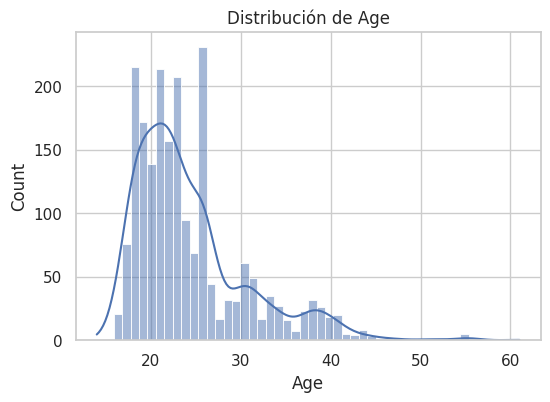

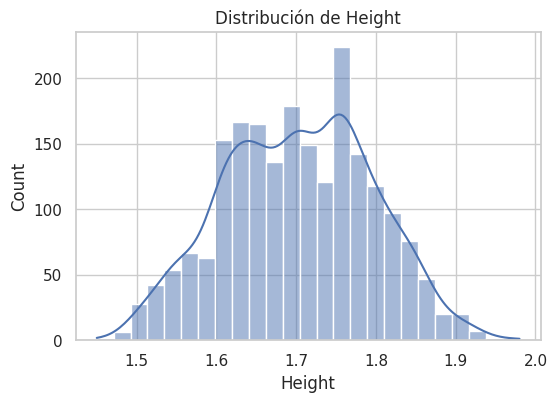

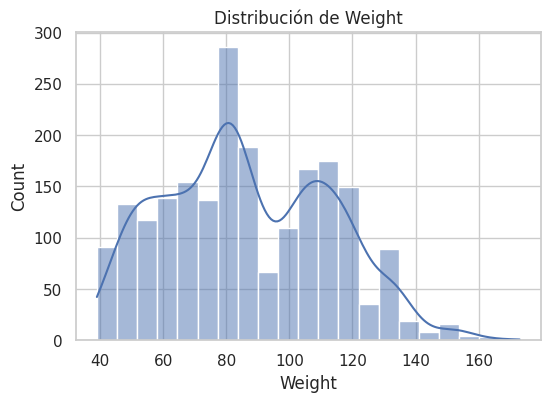

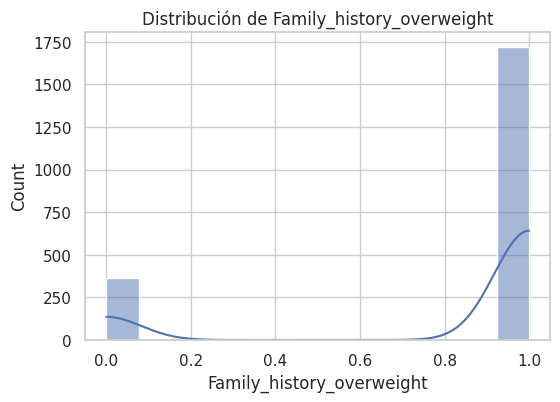

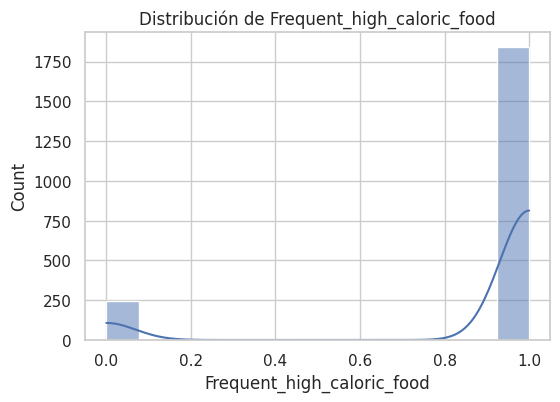

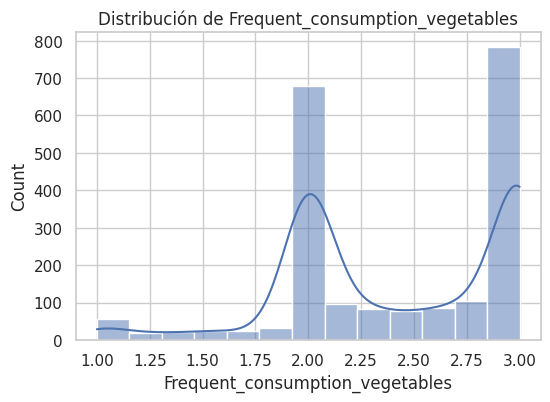

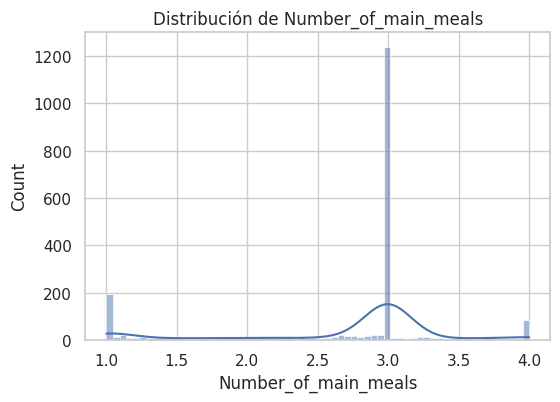

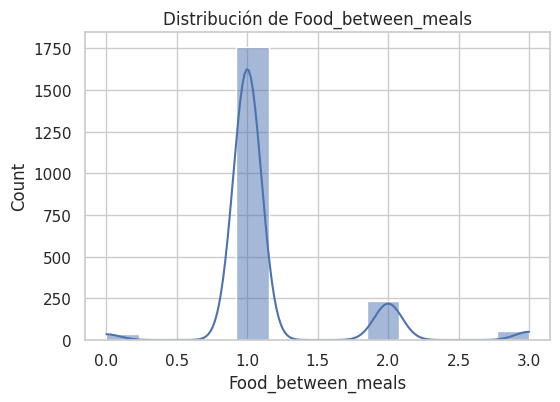

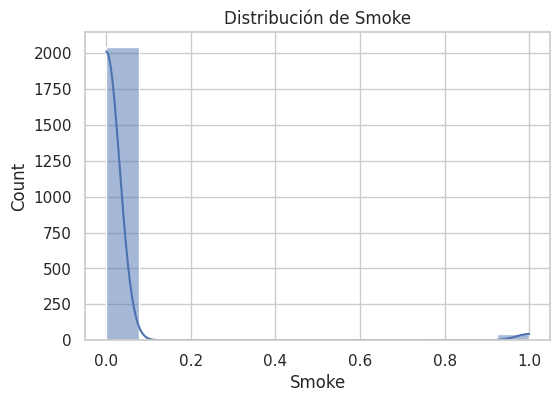

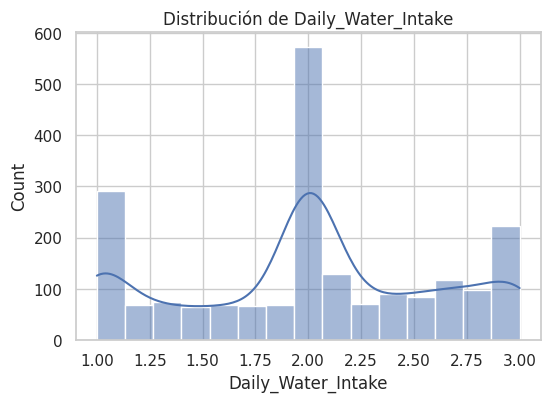

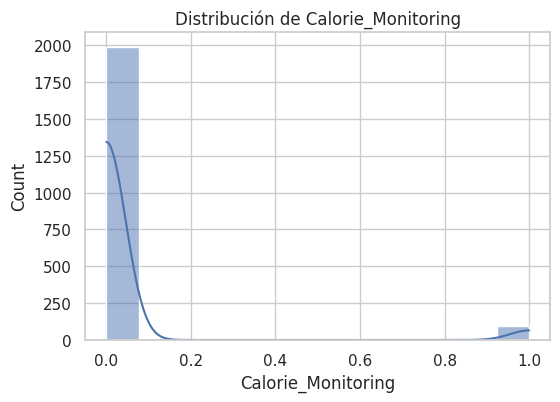

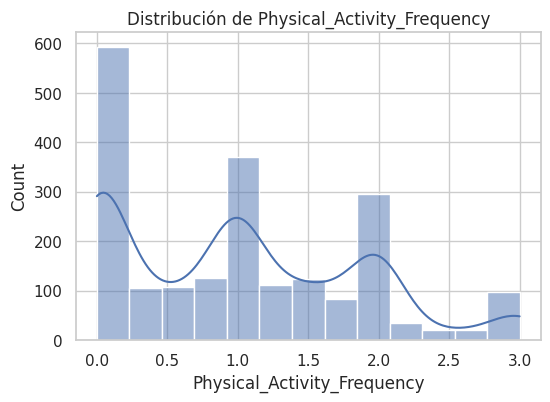

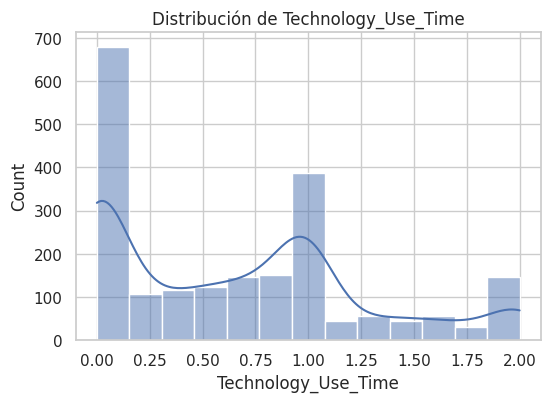

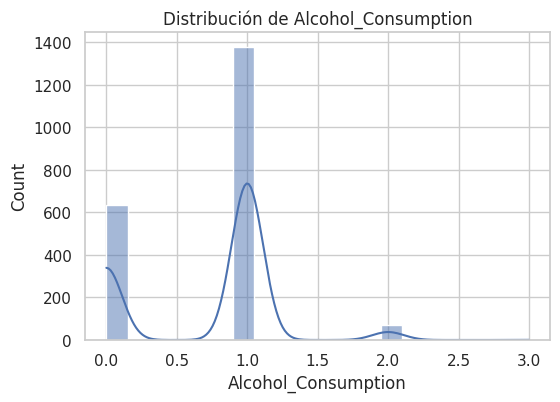

In [ ]:
#VISUALIZACIONES
#Histograma y KDE
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(Obesidad_DataSet[col], kde=True)
    plt.title(f"Distribución de {col}")
    plt.show()

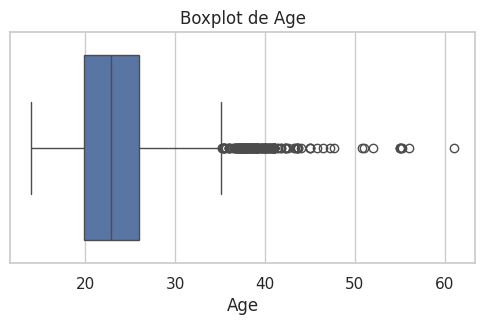

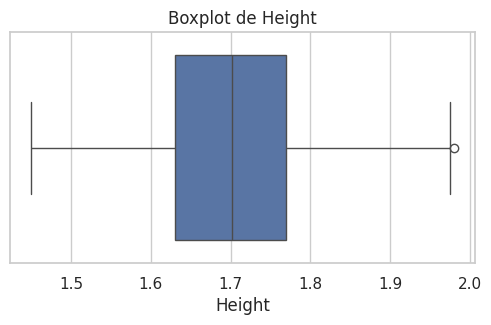

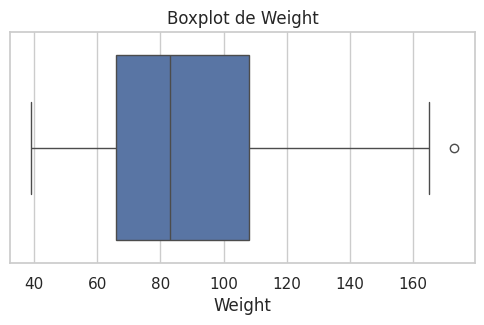

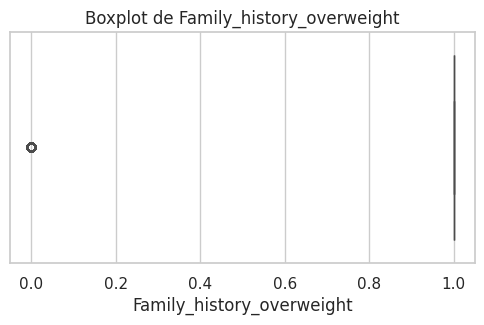

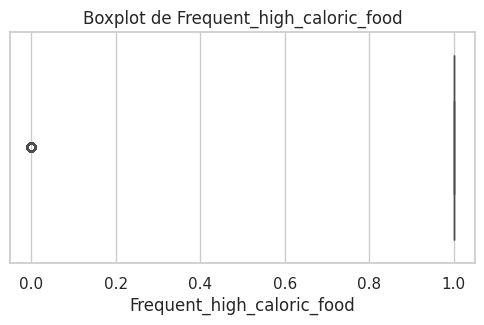

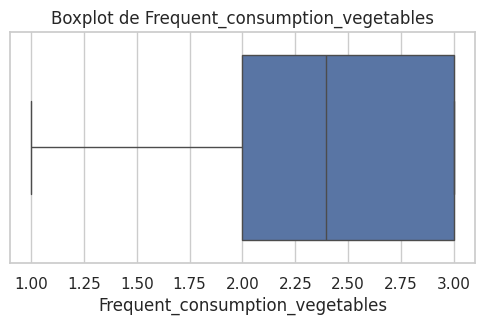

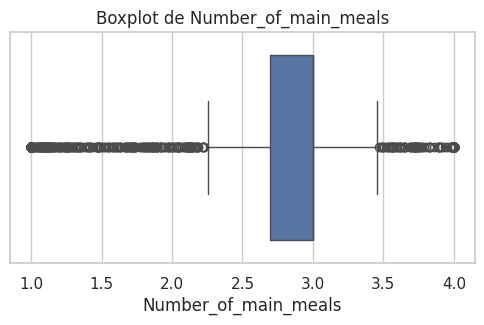

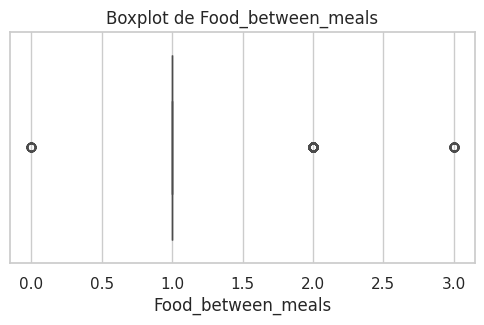

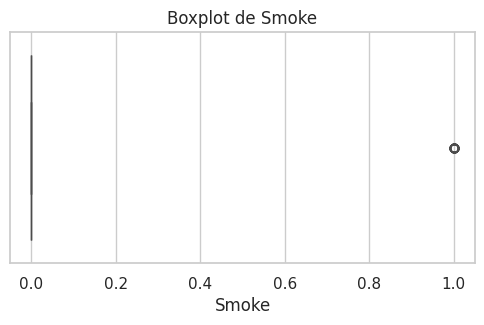

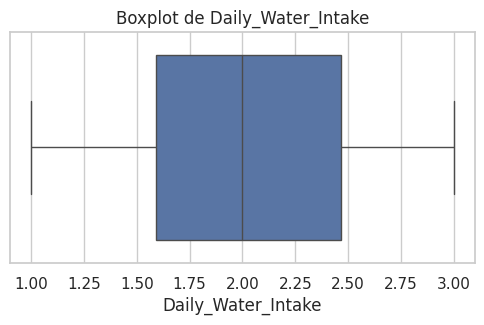

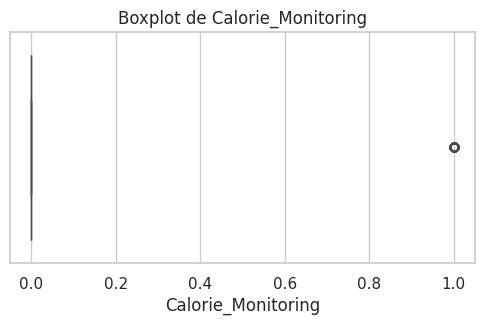

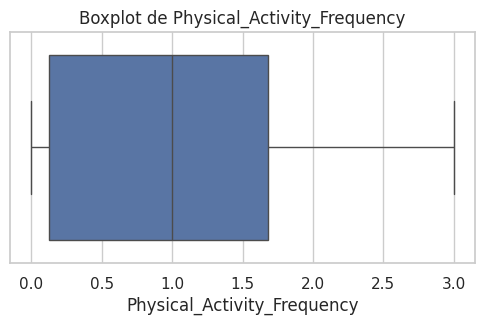

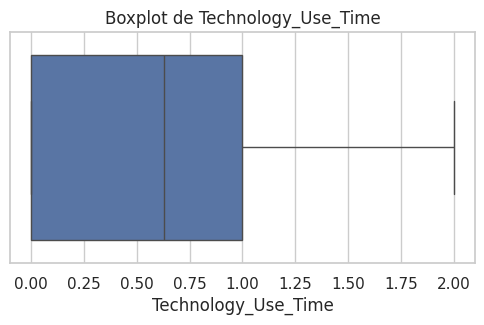

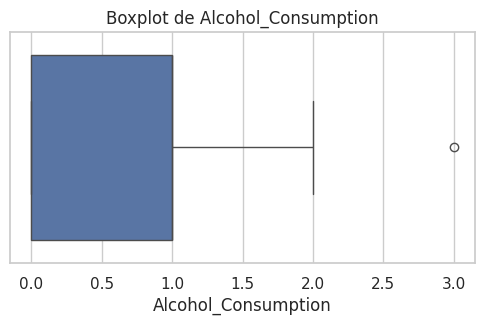

In [ ]:
#Boxplots (outliers)
for col in num_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=Obesidad_DataSet[col])
    plt.title(f"Boxplot de {col}")
    plt.show()

### ***Analisis variables categóricas***


In [ ]:
#Analisis de frecuencias
for col in cat_cols:
    print(f"\n {col}")
    print(Obesidad_DataSet[col].value_counts())


 Gender
Gender
Male      1052
Female    1035
Name: count, dtype: int64

 Transportation_type
Transportation_type
Public_Transportation    1558
Automobile                456
Walking                    55
Motorbike                  11
Bike                        7
Name: count, dtype: int64

 Obesity_Level
Obesity_Level
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267
Name: count, dtype: int64


In [ ]:
#Categorias dominantes
for col in cat_cols:
    print(f"\n Categoría dominante en {col}")
    print(Obesidad_DataSet[col].value_counts().idxmax())


 Categoría dominante en Gender
Male

 Categoría dominante en Transportation_type
Public_Transportation

 Categoría dominante en Obesity_Level
Obesity_Type_I


In [ ]:
#Categorías atipicas
for col in cat_cols:
    print(f"\n Categorías atipicas en {col}")
    print(Obesidad_DataSet[col].value_counts()[Obesidad_DataSet[col].value_counts() < 50])


 Categorías atipicas en Gender
Series([], Name: count, dtype: int64)

 Categorías atipicas en Transportation_type
Transportation_type
Motorbike    11
Bike          7
Name: count, dtype: int64

 Categorías atipicas en Obesity_Level
Series([], Name: count, dtype: int64)


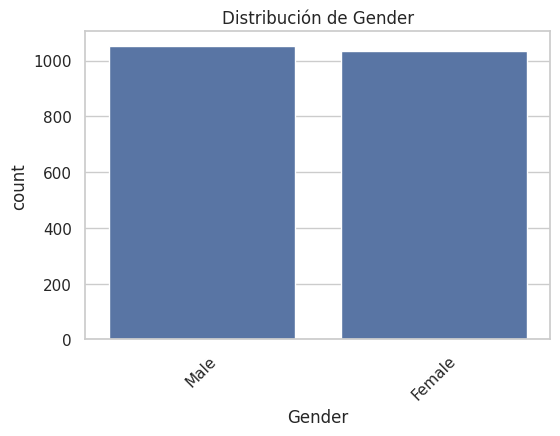

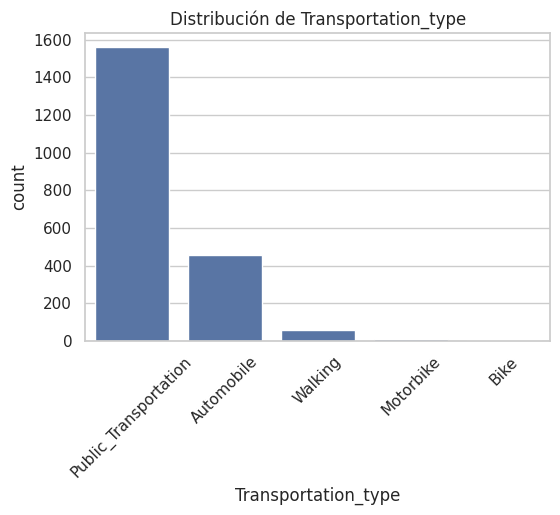

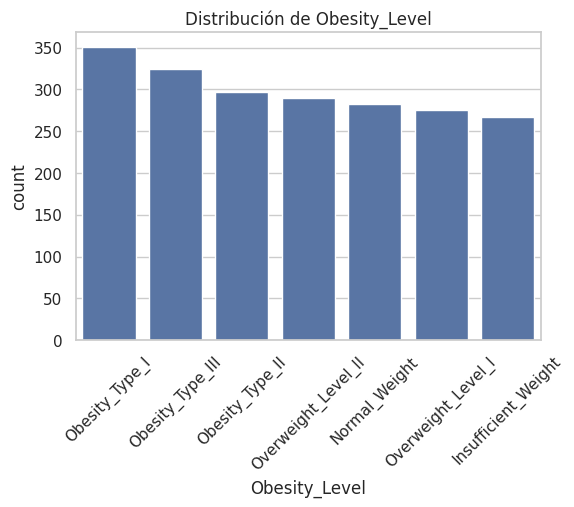

In [ ]:
#Grafica de frecuencias
for col in cat_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(data=Obesidad_DataSet, x=col, order=Obesidad_DataSet[col].value_counts().index)
    plt.xticks(rotation=45)
    plt.title(f"Distribución de {col}")
    plt.show()

## **Análisis de relaciones entre variables**

### ***Numérica vs Númerica***

Edad vs Peso para determinar si la edad es un factor de riesgo para la obesidad

In [ ]:
#Prueba de normalidad a las variables para determinar la prueba de crrelación a usar

##Variable Altura

stat, p = stats.shapiro(Obesidad_DataSet["Age"])

print("Age")
print("Estadístico:", stat)
print("p-value:", p)

if p > 0.05:
    print("✅ Distribución NORMAL \n")
else:
    print("❌ Distribución NO normal \n")

## Variable Peso
stat, p = stats.shapiro(Obesidad_DataSet["Weight"])

print("Weight")
print("Estadístico:", stat)
print("p-value:", p)

if p > 0.05:
    print("✅ Distribución NORMAL \n")
else:
    print("❌ Distribución NO normal \n")


Age
Estadístico: 0.8678946521313857
p-value: 8.447894961354417e-39
❌ Distribución NO normal 

Weight
Estadístico: 0.9769171798417503
p-value: 7.269513591904046e-18
❌ Distribución NO normal 



**Resultado:** Se observa que no hay Normalidad en las variables de Altura y Peso por lo que se Usará Spearman para medir la correlación

In [ ]:
from scipy.stats import spearmanr

corr, p_value = spearmanr(Obesidad_DataSet["Age"], Obesidad_DataSet["Weight"])
print("Correlación:", corr)
print("p-value:", p_value)

Correlación: 0.3502958220031897
p-value: 2.6585999456467975e-61


**Interpretación:** La relación es estadísticamente significativa. Existe una relación positiva moderada-débil entre Edad y Peso. A medida que aumenta la edad, el peso tiende a aumentar pero, no de forma fuerte.

### ***Categórica vs Categórica***

Sexo vs Nivel de Obesidad para determinar si hay un género que predomine en los niveles de Obesidad.

In [ ]:
tabla_genero_obesidad = pd.crosstab(
    Obesidad_DataSet["Gender"],
    Obesidad_DataSet["Obesity_Level"]
)

tabla_genero_obesidad

Obesity_Level,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Gender,,,,,,,
Female,169,137,156,2,323,145,103
Male,98,145,195,295,1,131,187


In [ ]:
tabla_genero_obesidad_norm = pd.crosstab(
    Obesidad_DataSet["Gender"],
    Obesidad_DataSet["Obesity_Level"],
    normalize="index"
)*100

tabla_genero_obesidad_norm.round(2).astype(str)+ "%"

Obesity_Level,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Gender,,,,,,,
Female,16.33%,13.24%,15.07%,0.19%,31.21%,14.01%,9.95%
Male,9.32%,13.78%,18.54%,28.04%,0.1%,12.45%,17.78%


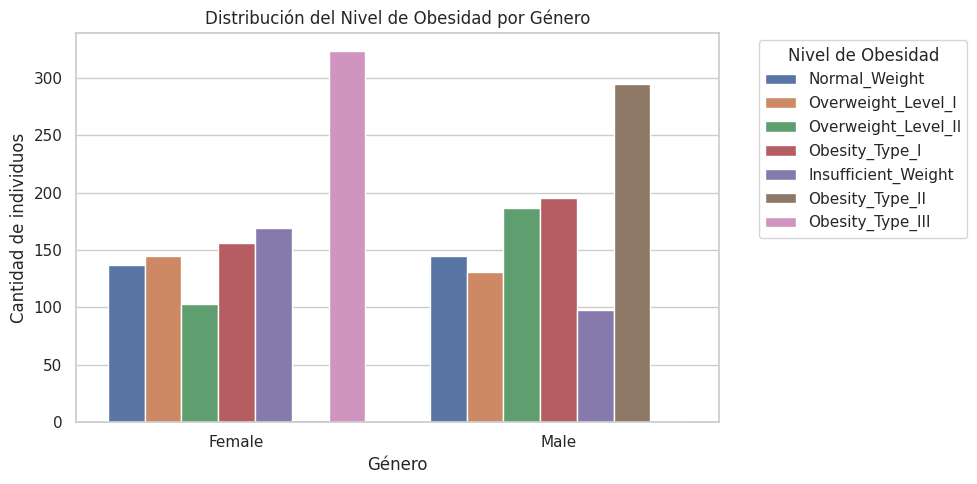

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(
    data=Obesidad_DataSet,
    x="Gender",
    hue="Obesity_Level"
)
plt.title("Distribución del Nivel de Obesidad por Género")
plt.xlabel("Género")
plt.ylabel("Cantidad de individuos")
plt.xticks(rotation=0)
plt.legend(
    title="Nivel de Obesidad",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

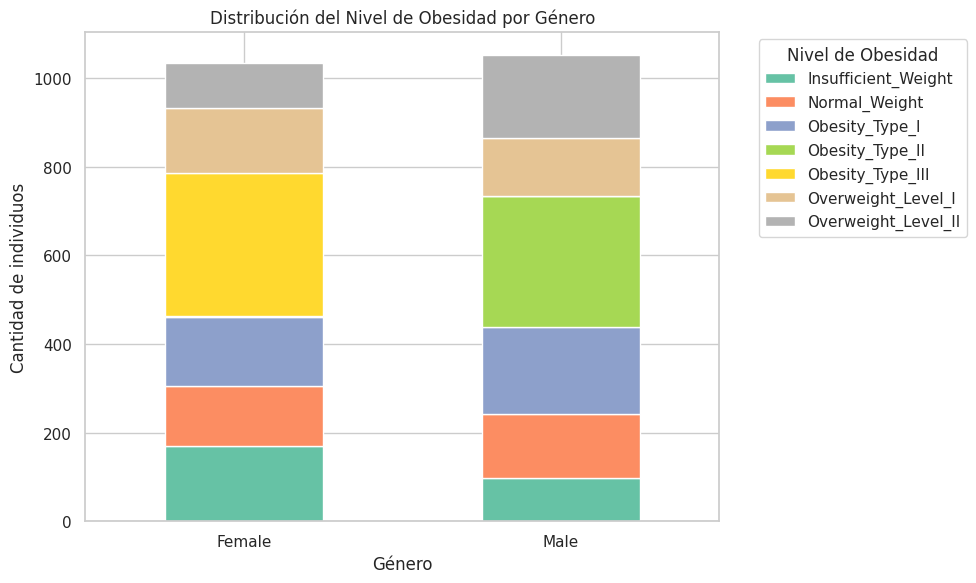

In [ ]:
tabla_genero_obesidad.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6),
    colormap="Set2"
)

plt.title("Distribución del Nivel de Obesidad por Género")
plt.xlabel("Género")
plt.ylabel("Cantidad de individuos")
plt.xticks(rotation=0)
plt.legend(
    title="Nivel de Obesidad",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(tabla_genero_obesidad)

print(f"Chi-cuadrado: {chi2:.3f}")
print(f"p-value: {p_value:.5f}")

if p_value < 0.05:
    print("✅ Existe una relación estadísticamente significativa entre el género y el nivel de obesidad.")
else:
    print("❌ No se evidencia una relación estadísticamente significativa entre el género y el nivel de obesidad.")


Chi-cuadrado: 657.453
p-value: 0.00000
✅ Existe una relación estadísticamente significativa entre el género y el nivel de obesidad.


**Interpretación:**
El resultado del analisis gráfico, se observan diferencias en la distribución de los niveles de obesidad entre hombres y mujeres evidenciando que algunos niveles se concentran en un genero especifico, por lo cual se evidencia que existe una relación entre el genero y el nivel de obesidad por lo que el genero podría considerarse un factor relevante en el analisis de esta variable

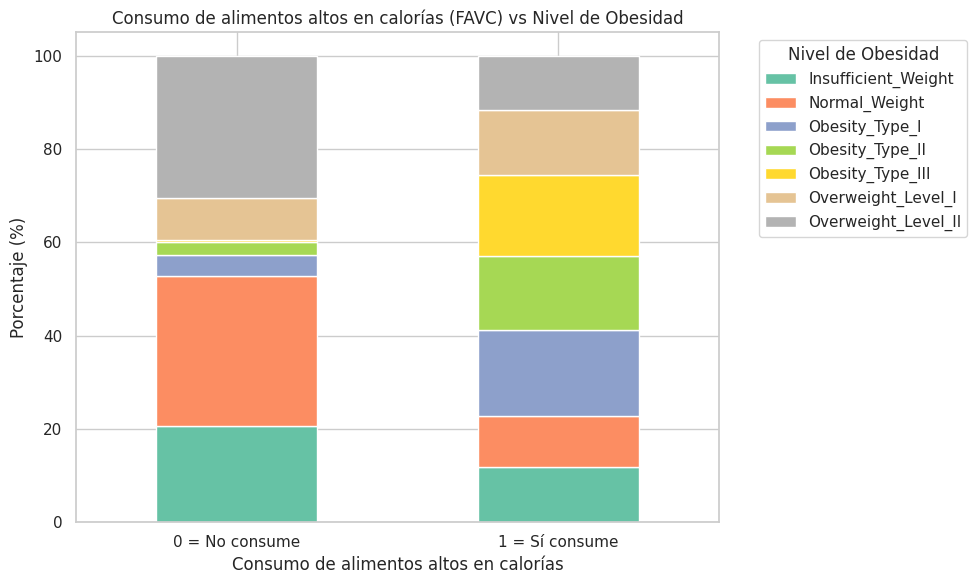

In [ ]:
#Consumo de alimentos altos en calorías (FAVC) vs Obesidad


tabla_favc = pd.crosstab(
    Obesidad_DataSet["Frequent_high_caloric_food"],
    Obesidad_DataSet["Obesity_Level"],
    normalize="index"
).mul(100).round(2)

tabla_favc


#Gráfica con etiquetas personalizadas (0 y 1)


ax = tabla_favc.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6),
    colormap="Set2"
)

# Etiquetas personalizadas para el eje X
ax.set_xticklabels(
    ["0 = No consume", "1 = Sí consume"],
    rotation=0
)

# Títulos y etiquetas
plt.title("Consumo de alimentos altos en calorías (FAVC) vs Nivel de Obesidad")
plt.xlabel("Consumo de alimentos altos en calorías")
plt.ylabel("Porcentaje (%)")

# Leyenda
plt.legend(
    title="Nivel de Obesidad",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

**Interpretación:**

Se observa que las personas que consumen frecuentemente alimentos altos en calorías presentan una mayor proporción en los niveles elevados de obesidad. La prueba Chi‑cuadrado confirma que esta relación es estadísticamente significativa, lo que sugiere que el consumo de alimentos altos en calorías está asociado con el nivel de obesidad.


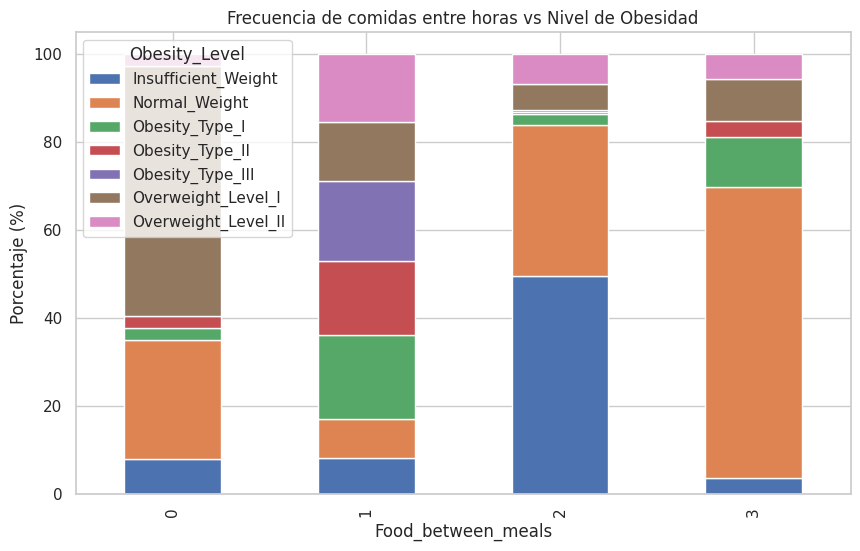

In [ ]:
#Comidas entre horas (CAEC) vs Obesidad
#Tabla en %

tabla_caec = pd.crosstab(
    Obesidad_DataSet["Food_between_meals"],
    Obesidad_DataSet["Obesity_Level"],
    normalize="index"
).mul(100).round(2)

tabla_caec

#Gráfica

tabla_caec.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6)
)
plt.ylabel("Porcentaje (%)")
plt.title("Frecuencia de comidas entre horas vs Nivel de Obesidad")
plt.show()

**Interpretación:**

Se identifica una tendencia creciente en los niveles de obesidad a medida que aumenta la frecuencia de consumo de alimentos entre comidas, lo que indica que este hábito podría estar relacionado con un mayor nivel de obesidad.


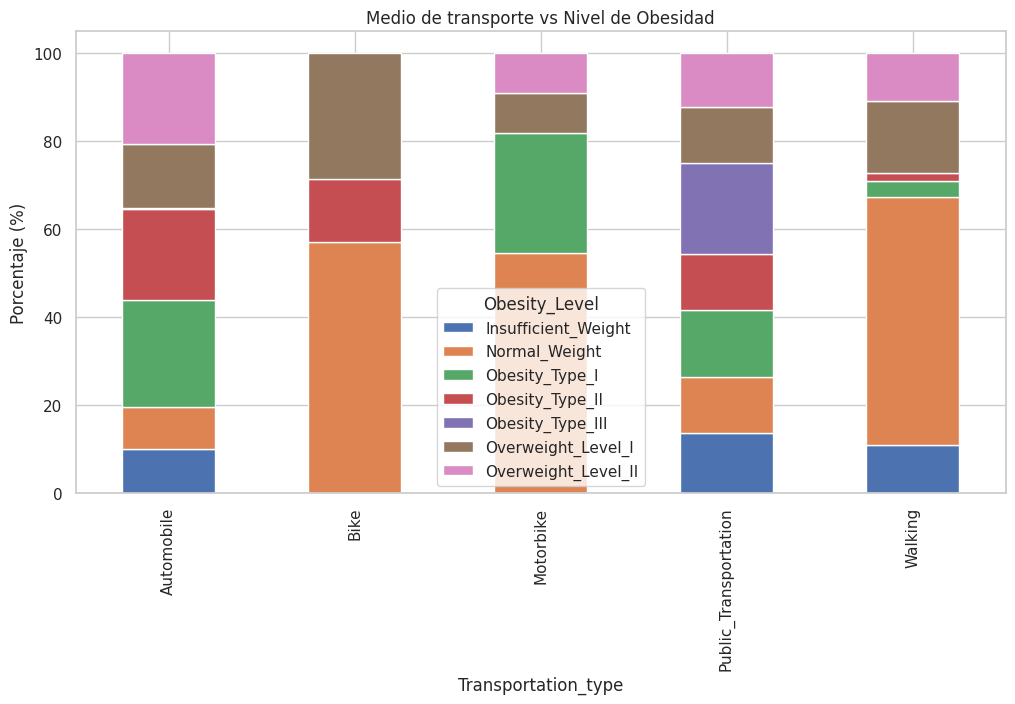

In [ ]:
#Medio de transporte (MTRANS) vs Obesidad

tabla_transporte = pd.crosstab(
    Obesidad_DataSet["Transportation_type"],
    Obesidad_DataSet["Obesity_Level"],
    normalize="index"
).mul(100).round(2)

#Gráfica

tabla_transporte.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)
plt.ylabel("Porcentaje (%)")
plt.title("Medio de transporte vs Nivel de Obesidad")
plt.show()

**Interpretación:**
Los medios de transporte pasivos presentan mayores proporciones en niveles elevados de obesidad, mientras que los medios activos muestran una mayor presencia en niveles normales o bajos de obesidad.

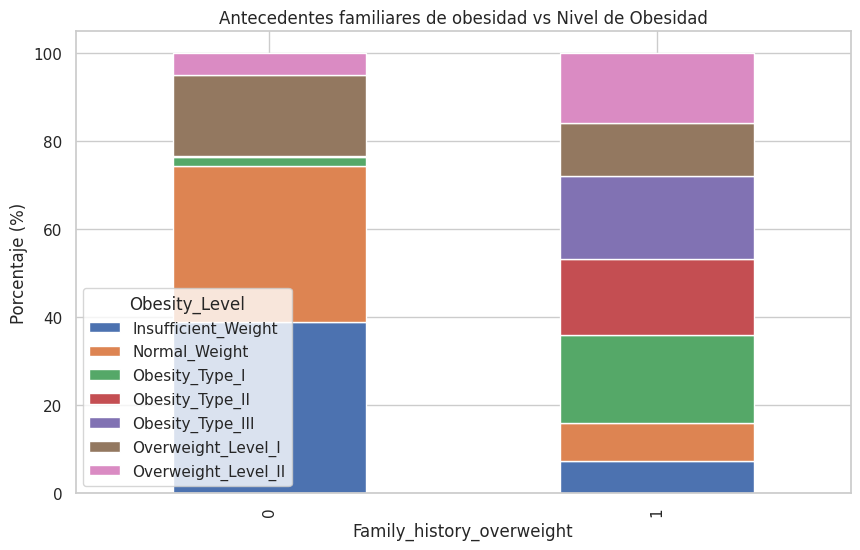

In [ ]:
#Antecedentes familiares vs Obesidad
 #Tabla en %

tabla_familiar = pd.crosstab(
    Obesidad_DataSet["Family_history_overweight"],
    Obesidad_DataSet["Obesity_Level"],
    normalize="index"
).mul(100).round(2)

tabla_familiar

#Gráfica

tabla_familiar.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6)
)
plt.ylabel("Porcentaje (%)")
plt.title("Antecedentes familiares de obesidad vs Nivel de Obesidad")
plt.show()

**Interpretación:**
Se evidencia que los individuos con antecedentes familiares de obesidad presentan una mayor proporción en los niveles más altos de obesidad, lo que sugiere una posible influencia genética y/o de hábitos familiares.

### ***Númerica vs Categórica***


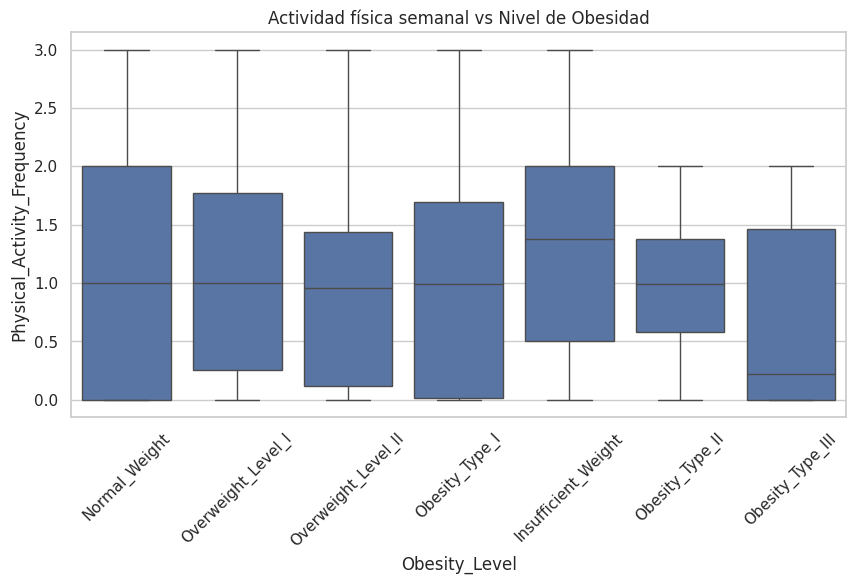

In [ ]:
#Actividad física (FAF) vs Obesidad
 #Boxplot

plt.figure(figsize=(10,5))
sns.boxplot(
    data=Obesidad_DataSet,
    x="Obesity_Level",
    y="Physical_Activity_Frequency"
)
plt.xticks(rotation=45)
plt.title("Actividad física semanal vs Nivel de Obesidad")
plt.show()

**Interpretación:**

Los niveles más altos de obesidad presentan, en promedio, una menor frecuencia de actividad física semanal, lo que sugiere una relación inversa entre la actividad física y el nivel de obesidad.

## **Creación de Features**

In [ ]:
#Índice de hábitos poco saludables (variable compuesta)

Obesidad_DataSet["Unhealthy_Habits_Index"] = (
    Obesidad_DataSet["Frequent_high_caloric_food"] +
    Obesidad_DataSet["Food_between_meals"] +
    (3 - Obesidad_DataSet["Frequent_consumption_vegetables"]) +
    Obesidad_DataSet["Alcohol_Consumption"]
)

#Nivel de sedentarismo

Obesidad_DataSet["Sedentary_Level"] = (
    Obesidad_DataSet["Technology_Use_Time"] -
    Obesidad_DataSet["Physical_Activity_Frequency"]
)

#Clasificación de actividad física (baja / media / alta)

Obesidad_DataSet["Physical_Activity_Level"] = pd.cut(
    Obesidad_DataSet["Physical_Activity_Frequency"],
    bins=[-1, 1, 3, 10],
    labels=["Baja", "Media", "Alta"]
)

#Transporte activo vs pasivo

transporte_activo = ["Walking", "Bike"]

Obesidad_DataSet["Active_Transport"] = Obesidad_DataSet["Transportation_type"].isin(
    transporte_activo
).astype(int)

#Riesgo familiar + hábitos (interacción)

Obesidad_DataSet["Family_Risk_x_Habits"] = (
    Obesidad_DataSet["Family_history_overweight"] *
    Obesidad_DataSet["Unhealthy_Habits_Index"]
)

#Clasificación de consumo de agua (adecuado / bajo)

Obesidad_DataSet["Water_Intake_Level"] = pd.cut(
    Obesidad_DataSet["Daily_Water_Intake"],
    bins=[0, 1.5, 3, 10],
    labels=["Bajo", "Adecuado", "Alto"]
)

#Clasificación edad
Obesidad_DataSet["Age_Group"] = pd.cut(
    Obesidad_DataSet["Age"],
    bins=[0, 18, 30, 45, 100],
    labels=["Adolescente", "Adulto joven", "Adulto", "Adulto mayor"]
)

##Formulación del objetivo y Split reproducible

In [ ]:
# ==========================================
# 1. CREACIÓN DE LA VARIABLE OBJETIVO BINARIA
# ==========================================
# 1 = Presenta algún tipo de Obesidad, 0 = No presenta Obesidad (Normal/Sobrepeso/Insuficiente)
df_obesidad["riesgo_obesidad"] = df_obesidad["Obesity_Level"].apply(
    lambda x: 1 if "Obesity" in x else 0
)

# ==========================================
# 2. SEPARACIÓN DE CARACTERÍSTICAS (X) Y OBJETIVO (y)
# ==========================================
# Eliminamos la etiqueta original de 7 clases y la nueva variable objetivo binaria
X = df_obesidad.drop(columns=["Obesity_Level", "riesgo_obesidad"])
y = df_obesidad["riesgo_obesidad"]

# Identificación de tipos de columnas
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

# ==========================================
# 3. DIVISION TRAIN / TEST (80% / 20% o 75% / 25%)
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE
)

print("--- REPORTE DE DIVISIÓN DE DATOS ---")
print(f"Total registros: {len(df_obesidad)}")
print(f"Entrenamiento (X_train): {X_train.shape[0]} filas | {X_train.shape[1]} columnas")
print(f"Prueba (X_test): {X_test.shape[0]} filas | {X_test.shape[1]} columnas")
print(f"\nDistribución del Target en Train (%):\n{y_train.value_counts(normalize=True)}")

--- REPORTE DE DIVISIÓN DE DATOS ---
Total registros: 2087
Entrenamiento (X_train): 1565 filas | 16 columnas
Prueba (X_test): 522 filas | 16 columnas

Distribución del Target en Train (%):
riesgo_obesidad
0   0.534
1   0.466
Name: proportion, dtype: float64


##**FASE 2: Experiment Tracking**

##Inicialización de MLflow

In [ ]:
# Configuración del experimento en MLflow
mlflow.set_experiment("Riesgo_Obesidad_MLOps")

print("✅ Experimento de MLflow iniciado: 'Riesgo_Obesidad_MLOps'")

✅ Experimento de MLflow iniciado: 'Riesgo_Obesidad_MLOps'


##Comparación de Algoritmos con Tracking Automático

In [ ]:
# ==========================================
# 1. PIPELINES DE PREPROCESAMIENTO POR TIPO DE COLUMNA
# ==========================================

# Pipeline para columnas numéricas: Imputación con la mediana + Escalado estándar
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline para columnas categóricas: Imputación con el valor más frecuente + OneHotEncoder
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

# ==========================================
# 2. UNIÓN DE PREPROCESADORES CON COLUMNTRANSFORMER
# ==========================================
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols)
    ]
)

# ==========================================
# 3. CONSTRUCCIÓN DEL PIPELINE COMPLETO CON MODELO BASE
# ==========================================
logit_model = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))
])

# ==========================================
# 4. ENTRENAMIENTO DEL MODELO (Solo sobre X_train)
# ==========================================
logit_model.fit(X_train, y_train)

print("✅ Pipeline preprocesado y modelo de Regresión Logística entrenado exitosamente únicamente sobre X_train.")

✅ Pipeline preprocesado y modelo de Regresión Logística entrenado exitosamente únicamente sobre X_train.


In [ ]:
# Importamos modelos adicionales para comparar
from sklearn.ensemble import RandomForestClassifier

# Definimos los modelos a experimentar
modelos = {
    "Regresion_Logistica": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random_Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=RANDOM_STATE)
}

# Bucle de experimentos con MLflow Tracking
for nombre_modelo, clf in modelos.items():
    with mlflow.start_run(run_name=nombre_modelo):
        # 1. Construir el Pipeline
        pipeline_exp = Pipeline(steps=[
            ("prep", preprocessor),
            ("clf", clf)
        ])

        # 2. Entrenar sobre X_train
        pipeline_exp.fit(X_train, y_train)

        # 3. Predicciones
        y_pred_exp = pipeline_exp.predict(X_test)
        y_pred_proba_exp = pipeline_exp.predict_proba(X_test)[:, 1]

        # 4. Calcular métricas
        acc = accuracy_score(y_test, y_pred_exp)
        prec = precision_score(y_test, y_pred_exp)
        rec = recall_score(y_test, y_pred_exp)
        f1 = f1_score(y_test, y_pred_exp)
        auc = roc_auc_score(y_test, y_pred_proba_exp)

        # 5. Registrar parámetros y métricas en MLflow
        mlflow.log_param("algoritmo", nombre_modelo)
        mlflow.log_metric("accuracy", acc)
        mlflow.log_metric("precision", prec)
        mlflow.log_metric("recall", rec)
        mlflow.log_metric("f1_score", f1)
        mlflow.log_metric("roc_auc", auc)

        # 6. Guardar el artefacto del modelo en MLflow
        mlflow.sklearn.log_model(
            sk_model=pipeline_exp,
            artifact_path="model",
            serialization_format="pickle"
            )

        print(f"🔹 [{nombre_modelo}] registrado exitosamente en MLflow | ROC-AUC: {auc:.4f} | Recall: {rec:.4f}")

2026/10/12 16:45:21 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/12 16:45:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🔹 [Regresion_Logistica] registrado exitosamente en MLflow | ROC-AUC: 0.9999 | Recall: 0.9918


2026/10/12 16:45:42 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/12 16:45:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🔹 [Random_Forest] registrado exitosamente en MLflow | ROC-AUC: 0.9992 | Recall: 0.9835


##Registro del Mejor Modelo (Model Registry)

In [ ]:
# Consulta de los experimentos en MLflow
df_runs = mlflow.search_runs(experiment_names=["Riesgo_Obesidad_MLOps"])

# Ordenamos por ROC-AUC para identificar el mejor
df_runs_sorted = df_runs.sort_values(by="metrics.roc_auc", ascending=False)

print("--- TABLA COMPARATIVA DE EXPERIMENTOS (MLFLOW) ---")
display(df_runs_sorted[["run_id", "params.algoritmo", "metrics.roc_auc", "metrics.recall", "metrics.f1_score"]])

best_run = df_runs_sorted.iloc[0]
print(f"\n🏆 MEJOR MODELO ENCONTRADO: {best_run['params.algoritmo']} con ROC-AUC = {best_run['metrics.roc_auc']:.4f}")

--- TABLA COMPARATIVA DE EXPERIMENTOS (MLFLOW) ---


,run_id,params.algoritmo,metrics.roc_auc,metrics.recall,metrics.f1_score
1,98405b2e342f45babf2dc8f20db1530b,Regresion_Logistica,1.000,0.992,0.990
0,2a7c7e6e4aed43ea8da1c970d52ce21c,Random_Forest,0.999,0.984,0.984
2,7dde5dabf0bf449f86809481e7d559ae,None,NaN,NaN,NaN
3,ec407b7a2818412384ddcaaf30c9ba33,None,NaN,NaN,NaN
4,6830fd5463fc4a8786ab67ed9a6ae02d,None,NaN,NaN,NaN



🏆 MEJOR MODELO ENCONTRADO: Regresion_Logistica con ROC-AUC = 0.9999


In [ ]:
model_uri = f"runs:/{best_run['run_id']}/model"

print("Mejor modelo seleccionado:")
print(model_uri)

Mejor modelo seleccionado:
runs:/98405b2e342f45babf2dc8f20db1530b/model


In [ ]:
try:

    mlflow.register_model(
        model_uri=model_uri,
        name="Obesity_Risk_Model"
    )

    print(
        "✅ Modelo registrado en MLflow Registry"
    )

except Exception as e:

    print(
        "No fue posible registrar el modelo:",
        e
    )

Successfully registered model 'Obesity_Risk_Model'.
2026/10/12 16:49:52 WARNING mlflow.tracking._model_registry.fluent: Run with id 98405b2e342f45babf2dc8f20db1530b has no artifacts at artifact path 'model', registering model based on models:/m-87d40c1ba33342a29a9689bc7299bb83 instead


✅ Modelo registrado en MLflow Registry


Created version '1' of model 'Obesity_Risk_Model'.


In [ ]:
!pip install prefect -q

In [ ]:
from prefect import flow, task

In [ ]:
@task
def cargar_datos():

    print("Datos cargados")

    return df_obesidad


@task
def crear_target(df):

    df["riesgo_obesidad"] = df["Obesity_Level"].apply(
        lambda x: 1 if "Obesity" in x else 0
    )

    return df

In [ ]:
@flow(name="Pipeline_Obesity_MLOps")

def entrenamiento_prefect():

    df = cargar_datos()

    df = crear_target(df)

    print("Pipeline ejecutado correctamente")


entrenamiento_prefect()

INFO:prefect.flow_runs:Beginning flow run 'indigo-robin' for flow 'Pipeline_Obesity_MLOps'
INFO:prefect.task_runs:Finished in state Completed()
INFO:prefect.task_runs:Finished in state Completed()


Datos cargados
Pipeline ejecutado correctamente


INFO:prefect.flow_runs:Finished in state Completed()


## **FASE 3: Pipeline de Entrenamiento**

##Evaluación del Modelo Base (Métricas de Clasificación)

In [ ]:
# ==========================================
# 1. PREDICCIONES Y PROBABILIDADES SOBRE X_TEST
# ==========================================
y_pred = logit_model.predict(X_test)
y_pred_proba = logit_model.predict_proba(X_test)[:, 1]

# ==========================================
# 2. CÁLCULO DE MÉTRICAS INDIVIDUALES
# ==========================================
print("--- MÉTRICAS DE EVALUACIÓN (CONJUNTO DE PRUEBA) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_pred_proba):.4f}")

print("\n--- REPORTE DE CLASIFICACIÓN DETALLADO ---")
print(classification_report(y_test, y_pred, target_names=["Sin Riesgo", "Con Riesgo"]))

--- MÉTRICAS DE EVALUACIÓN (CONJUNTO DE PRUEBA) ---
Accuracy:  0.9904
Precision: 0.9877
Recall:    0.9918
F1-Score:  0.9897
ROC-AUC:   0.9999

--- REPORTE DE CLASIFICACIÓN DETALLADO ---
              precision    recall  f1-score   support

  Sin Riesgo       0.99      0.99      0.99       279
  Con Riesgo       0.99      0.99      0.99       243

    accuracy                           0.99       522
   macro avg       0.99      0.99      0.99       522
weighted avg       0.99      0.99      0.99       522



##Matriz de Confusión

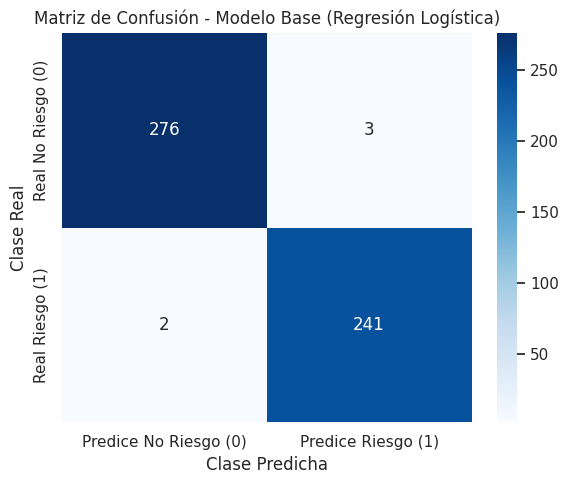

In [ ]:
# ==========================================
# CÁLCULO Y GRAFICADO DE LA MATRIZ DE CONFUSIÓN
# ==========================================
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predice No Riesgo (0)", "Predice Riesgo (1)"],
    yticklabels=["Real No Riesgo (0)", "Real Riesgo (1)"]
)
plt.title("Matriz de Confusión - Modelo Base (Regresión Logística)")
plt.ylabel("Clase Real")
plt.xlabel("Clase Predicha")
plt.tight_layout()
plt.show()

##Validación Cruzada Estratificada (CV)

In [ ]:
# ==========================================
# VALIDACIÓN CRUZADA CON STRATIFIED K-FOLD (5 FOLDS)
# ==========================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_scores = cross_val_score(
    logit_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("--- RESULTADOS DE VALIDACIÓN CRUZADA (ROC-AUC) ---")
print(f"Puntajes por cada Fold: {cv_scores.round(4)}")
print(f"ROC-AUC Promedio (CV):  {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

--- RESULTADOS DE VALIDACIÓN CRUZADA (ROC-AUC) ---
Puntajes por cada Fold: [1.     1.     1.     0.9995 0.9998]
ROC-AUC Promedio (CV):  0.9998 (+/- 0.0002)


##**Fase 4: Deployment**

##Desarrollo de la API REST con FastAPI

In [ ]:
%%writefile app.py
from fastapi import FastAPI
from pydantic import BaseModel, Field
import joblib
import pandas as pd

# 1. Inicialización de la aplicación FastAPI
app = FastAPI(
    title="API de Predicción de Riesgo de Obesidad",
    description="Microservicio MLOps para estimar el riesgo de obesidad basado en hábitos y condición física.",
    version="1.0.0"
)

# 2. Esquema de validación de datos de entrada (Pydantic)
class UserFeatures(BaseModel):
    Gender: str = Field(..., example="Female")
    Age: float = Field(..., example=21.0)
    Height: float = Field(..., example=1.62)
    Weight: float = Field(..., example=64.0)
    Family_history_overweight: str = Field(..., example="yes")
    Frequent_high_caloric_food: str = Field(..., example="no")
    Frequent_consumption_vegetables: float = Field(..., example=2.0)
    Number_of_main_meals: float = Field(..., example=3.0)
    Food_between_meals: str = Field(..., example="Sometimes")
    Smoke: str = Field(..., example="no")
    Daily_Water_Intake: float = Field(..., example=2.0)
    Calorie_Monitoring: str = Field(..., example="no")
    Physical_Activity_Frequency: float = Field(..., example=0.0)
    Technology_Use_Time: float = Field(..., example=1.0)
    Alcohol_Consumption: str = Field(..., example="no")
    Transportation_type: str = Field(..., example="Public_Transportation")

# 3. Endpoint de estado de salud del servicio (Healthcheck)
@app.get("/")
def health_check():
    return {"status": "ok", "message": "API de Riesgo de Obesidad activa y lista para recibir solicitudes."}

# 4. Endpoint principal de predicción
@app.post("/predict")
def predict_risk(data: UserFeatures):
    # Cargar el pipeline serializado
    model_pipeline = joblib.load("model_pipeline.pkl")

    # Convertir la entrada en DataFrame
    input_data = pd.DataFrame([data.dict()])

    # Inferencia
    prediction = model_pipeline.predict(input_data)[0]
    probability = model_pipeline.predict_proba(input_data)[0][1]

    return {
        "riesgo_obesidad_predicho": int(prediction),
        "probabilidad_riesgo": float(round(probability, 4)),
        "interpretacion": "Presenta Riesgo de Obesidad" if prediction == 1 else "No presenta Riesgo de Obesidad"
    }

Writing app.py


##Exportación del Modelo y Dockerfile

In [ ]:
import joblib

# 1. Serializar y guardar el pipeline entrenado
joblib.dump(logit_model, "model_pipeline.pkl")
print("✅ Artefacto 'model_pipeline.pkl' guardado exitosamente.")

# 2. Crear el archivo Dockerfile para la containerización del servicio
dockerfile_content = """
FROM python:3.10-slim

WORKDIR /app

# Copiar archivos del proyecto
COPY app.py /app/app.py
COPY model_pipeline.pkl /app/model_pipeline.pkl

# Instalar dependencias del sistema y de Python
RUN pip install --no-cache-dir fastapi uvicorn scikit-learn pandas joblib pydantic

EXPOSE 8000

CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
"""

with open("Dockerfile", "w") as f:
    f.write(dockerfile_content.strip())

print("✅ Archivo 'Dockerfile' generado exitosamente.")

✅ Artefacto 'model_pipeline.pkl' guardado exitosamente.
✅ Archivo 'Dockerfile' generado exitosamente.


##**Fase 5: Monitoreo**

In [ ]:
# ==========================================
# ESTRATEGIA DE MONITOREO Y DETECCIÓN DE DEGRADACIÓN (MLOPS)
# ==========================================

def plan_monitoreo_mlops():
    plan = {
        "1. Monitoreo de Data Drift (Deriva de Datos)": [
            "Comparar la distribución de variables clave (ej. Weight, Age, FAF) entre datos de entrenamiento y producción.",
            "Uso de pruebas estadísticas como Kolmogorov-Smirnov (variables continuas) y Chi-Cuadrado (variables categóricas).",
            "Métrica de alerta: Population Stability Index (PSI) > 0.2 indica deriva severa."
        ],
        "2. Monitoreo de Concept Drift (Deriva del Concepto)": [
            "Evaluar caídas en Precision, Recall y ROC-AUC a medida que se obtienen etiquetas reales de seguimiento médico.",
            "Alertar si el Recall cae por debajo del umbral crítico (e.g., Recall < 0.85)."
        ],
        "3. Monitoreo de Infraestructura": [
            "Latencia de inferencia en FastAPI (< 200 ms por solicitud).",
            "Tasa de errores HTTP 5xx/4xx y consumo de recursos (CPU, RAM) en Docker."
        ],
        "4. Estrategia de Re-entrenamiento (Retraining)": [
            "Re-entrenamiento programado automáticamente (e.g., cada 3 o 6 meses).",
            "Re-entrenamiento por evento (Triggered) cuando se detecte Data Drift significativo."
        ]
    }

    for seccion, puntos in plan.items():
        print(f"\n📌 {seccion}")
        for p in puntos:
            print(f"   • {p}")

plan_monitoreo_mlops()

##**FASE 6: Testing y Buenas Prácticas**

# ==========================================
# PRUEBAS UNITARIAS Y BUENAS PRÁCTICAS
# ==========================================

def test_pipeline_shape_and_predictions():
    sample_data = X_test.iloc[:5]

    preds = logit_model.predict(sample_data)
    assert len(preds) == 5, "La cantidad de predicciones no coincide con las entradas."
    assert set(preds).issubset({0, 1}), "Las predicciones deben ser exclusivamente 0 o 1."

    probs = logit_model.predict_proba(sample_data)[:, 1]
    assert len(probs) == 5, "La cantidad de probabilidades no coincide con las entradas."
    assert all(0.0 <= p <= 1.0 for p in probs), "Las probabilidades están fuera del rango [0, 1]."

    print("✅ Todas las pruebas unitarias pasaron exitosamente.")

test_pipeline_shape_and_predictions()

print("\n--- BUENAS PRÁCTICAS Y ESTÁNDARES DEL PROYECTO ---")
print("1. Formateo de Código: Configurado linter PEP8 (black / flake8).")
print("2. Gestión de Entorno: Proyecto configurado con 'uv' para reproducibilidad.")
print("3. Versionamiento: Repositorio GitHub enlazado con rastreo de experimentos en MLflow.")
print("4. Reproducibilidad: Semilla fija (RANDOM_STATE = 52).")


📌 1. Monitoreo de Data Drift (Deriva de Datos)
   • Comparar la distribución de variables clave (ej. Weight, Age, FAF) entre datos de entrenamiento y producción.
   • Uso de pruebas estadísticas como Kolmogorov-Smirnov (variables continuas) y Chi-Cuadrado (variables categóricas).
   • Métrica de alerta: Population Stability Index (PSI) > 0.2 indica deriva severa.

📌 2. Monitoreo de Concept Drift (Deriva del Concepto)
   • Evaluar caídas en Precision, Recall y ROC-AUC a medida que se obtienen etiquetas reales de seguimiento médico.
   • Alertar si el Recall cae por debajo del umbral crítico (e.g., Recall < 0.85).

📌 3. Monitoreo de Infraestructura
   • Latencia de inferencia en FastAPI (< 200 ms por solicitud).
   • Tasa de errores HTTP 5xx/4xx y consumo de recursos (CPU, RAM) en Docker.

📌 4. Estrategia de Re-entrenamiento (Retraining)
   • Re-entrenamiento programado automáticamente (e.g., cada 3 o 6 meses).
   • Re-entrenamiento por evento (Triggered) cuando se detecte Data Drift si

##**Fase 6: Testing y Best Practices**

##Pruebas Unitarias

In [ ]:
import pytest

# ==========================================
# PRUEBAS UNITARIAS PARA EL PIPELINE DE PREPRECESAMIENTO Y MODELO
# ==========================================

def test_pipeline_shape_and_predictions():
    """
    Verifica que el pipeline acepte la estructura de datos correcta y retorne dimensiones válidas.
    """
    # Tomamos un lote de prueba pequeño
    sample_data = X_test.iloc[:5]

    # 1. Probar predicción de clases (debe ser 0 o 1)
    preds = logit_model.predict(sample_data)
    assert len(preds) == 5, "La cantidad de predicciones no coincide con las entradas."
    assert set(preds).issubset({0, 1}), "Las predicciones deben ser exclusivamente 0 o 1."

    # 2. Probar probabilidades (deben estar entre 0.0 y 1.0)
    probs = logit_model.predict_proba(sample_data)[:, 1]
    assert len(probs) == 5, "La cantidad de probabilidades no coincide con las entradas."
    assert all(0.0 <= p <= 1.0 for p in probs), "Las probabilidades están fuera del rango [0, 1]."

    print("✅ Todas las pruebas unitarias pasaron exitosamente.")

# Ejecutar la prueba directa en el cuaderno
test_pipeline_shape_and_predictions()

✅ Todas las pruebas unitarias pasaron exitosamente.


##Documentación de Buenas Prácticas

In [ ]:
# ==========================================
# GUÍA DE CALIDAD DE CÓDIGO Y DOCUMENTACIÓN
# ==========================================

print("--- BUENAS PRÁCTICAS Y ESTÁNDARES DEL PROYECTO ---")
print("1. Formateo y Estilo de Código: Configurado linter PEP8 (black / flake8) para mantener consistencia.")
print("2. Manejo de Dependencias: Proyecto configurado mediante 'uv' y gestor de entornos aislados.")
print("3. Versionamiento de Artefactos: Repositorio en GitHub enlazado con rastreo de experimentos en MLflow.")
print("4. Reproducibilidad: Semilla aleatoria fija (RANDOM_STATE = 52) en splits y modelos.")

--- BUENAS PRÁCTICAS Y ESTÁNDARES DEL PROYECTO ---
1. Formateo y Estilo de Código: Configurado linter PEP8 (black / flake8) para mantener consistencia.
2. Manejo de Dependencias: Proyecto configurado mediante 'uv' y gestor de entornos aislados.
3. Versionamiento de Artefactos: Repositorio en GitHub enlazado con rastreo de experimentos en MLflow.
4. Reproducibilidad: Semilla aleatoria fija (RANDOM_STATE = 52) en splits y modelos.
